# Unit 3 group project: TrashNet + DINOv3 ConvNeXt Tiny

Compare frozen DINOv3 global pooled features with a linear softmax
classifier, an 8-unit GELU ANN, a larger ANN with dropout, and a training-majority
baseline. Test images are
held out for the group's eventual single final model. All modeling uses TensorFlow/Keras.


## 1. Compatible dependencies and configuration

Keep TensorFlow 2.20, required by Kaggle's existing TensorFlow add-ons, while
using Keras 3.15.1 to read the saved artifact. Pin Protobuf 5.29.5 and Kaggle within all reported consumers' supported ranges. Install the
missing BigQuery Storage dependency and compatible Gym version. Run `pip check`
before imports: dependency conflicts fail setup instead of being ignored.
Remove unused Dopamine (whose Gym requirement conflicts with Gymnax) and Google
Colab (whose pandas/Jupyter requirements conflict with Kaggle's server stack).
Remove unused legacy MoviePy, whose Decorator requirement conflicts with MNE.


In [33]:
# Install compatible pins before importing TensorFlow or dataset libraries.
import subprocess
import sys
import time

# Include dependency setup, extraction, training, scoring, and plots in runtime.
# perf_counter measures elapsed execution time; Kaggle queue time is excluded.
notebook_started = time.perf_counter()

# These unused preinstalled distributions impose mutually incompatible runtime
# constraints; removing them avoids changing Kaggle's pandas/Jupyter server.
subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y',
                'dopamine-rl', 'google-colab', 'moviepy'], check=True)
requirements = [
    'tensorflow==2.20.0', 'keras==3.15.1', 'datasets==5.1.0',
    'kagglehub==1.0.2', 'Pillow==12.3.0', 'protobuf==5.29.5',
    'huggingface-hub==1.31.0', 'google-cloud-bigquery-storage==2.35.0',
    'gym==0.26.2', 'decorator==5.3.1',
]
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet',
                '--disable-pip-version-check', *requirements], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'check'], check=True)


No broken requirements found.


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'check'], returncode=0)

In [34]:
import os
from pathlib import Path

# Set the backend before importing Keras, and reduce TensorFlow startup logging.
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import json
import numpy as np
import tensorflow as tf
# Configure allocation before loading weights or creating any GPU tensors.
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)
import keras
import kagglehub
from datasets import ClassLabel, Image, load_dataset
from IPython.display import display

DATASET_ID = "feyzazkefe/trashnet"
DATASET_REVISION = "kaggle-dataset-resized"
MODEL_HANDLE = "mataeoanderson/dinov3-convnext/keras/tiny/1"
MODEL_FILENAME = "dinov3_convnext_tiny.keras"
SAMPLE_INDEX = 0

# Relative paths work in Kaggle's writable working directory and local Jupyter.
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
SEED = 42
BATCH_SIZE = 64
MAX_EPOCHS = 50
PATIENCE = 5
keras.utils.set_random_seed(SEED)


TensorFlow: 2.20.0 | Keras: 3.15.1


## 2. Load TrashNet

Load the full training split from Kaggle's published Parquet conversion of the same dataset. All four shard filenames and the conversion commit were verified using the Hub's repository metadata. Using Parquet preserves the published label schema and avoids the image-folder loader's label-inference error on this repository.

`load_dataset("parquet", ..., split="train")` returns a `Dataset`. Its `image` feature decodes to a PIL image, and `label` is an integer described by `ClassLabel`. The class names come from that schema. No train/validation/test split is created yet.

API reference: [Hugging Face Parquet loading](https://huggingface.co/docs/datasets/en/loading#parquet).

In [35]:
from datasets import load_dataset, ClassLabel

DATA_DIR = "/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized"

dataset = load_dataset(
    "imagefolder",
    data_dir=DATA_DIR,
    split="train"
)

label_feature = dataset.features["label"]
assert isinstance(label_feature, ClassLabel)

class_names = label_feature.names

print(dataset)
print("Classes:", class_names)
print("Number of images:", len(dataset))

Resolving data files:   0%|          | 0/2527 [00:00<?, ?it/s]

Dataset({
    features: ['image', 'label'],
    num_rows: 2527
})
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Number of images: 2527


## 3. Show one image and its label

Read the label through `ClassLabel.int2str`; the display is the original RGB image, before model normalization.

Sample 0: cardboard (label 0)
Image size: (512, 384)


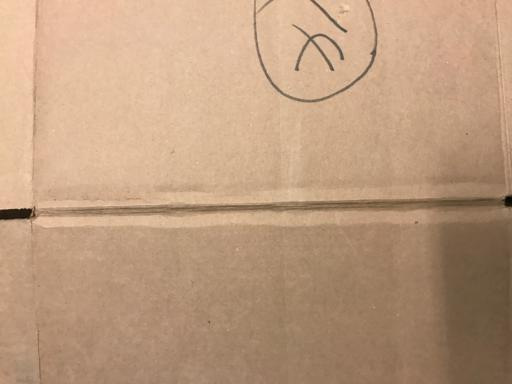

In [36]:
# A row contains image (PIL) and label (integer); any other columns are unused.
sample = dataset[SAMPLE_INDEX]
image = sample["image"].convert("RGB")
label_id = int(sample["label"])
label_name = label_feature.int2str(label_id)

print(f"Sample {SAMPLE_INDEX}: {label_name} (label {label_id})")
print("Image size:", image.size)
display(image)
# Save the same image so a completed Kaggle run has a downloadable preview.
image.save(OUTPUT_DIR / "sample_image.png")

## 4. Load only the Tiny CNN

`kagglehub.model_download` returns the local directory for the exact version. On Kaggle it resolves the attached model input; locally it downloads into KaggleHub's cache. The `.keras` file contains the architecture and weights and requires no custom layers.

The backbone produces features, not TrashNet class predictions. Freeze it as a starting point for the group's future classification head.

API references: [KaggleHub model download](https://github.com/Kaggle/kagglehub#download-models), [Keras model loading](https://keras.io/api/models/model_saving_apis/model_saving_and_loading/).

In [37]:
# Use the documented handle and filename; do not search for or load other variants.
model_dir = Path(kagglehub.model_download(MODEL_HANDLE))
model_file = model_dir / MODEL_FILENAME
if not model_file.is_file():
    raise FileNotFoundError(f"Expected model artifact: {MODEL_FILENAME}")

backbone = tf.keras.models.load_model(model_file, compile=False)
backbone.trainable = False
print("Loaded:", MODEL_HANDLE)
print("Model file:", model_file.name)
print("Parameters:", f"{backbone.count_params():,}")

Loaded: mataeoanderson/dinov3-convnext/keras/tiny/1
Model file: dinov3_convnext_tiny.keras
Parameters: 27,813,504


In [38]:
"""Reusable TensorFlow heads, frozen-feature caching, and train/dev reporting.

The notebook embeds this module so Kaggle needs only Notebook.ipynb. No helper
accepts a test feature array: test evaluation belongs to a later final-model run.
"""
import json
import math
from pathlib import Path

import keras
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from datasets import DatasetDict


def split_dataset(published, seed=42, test_fraction=0.15, validation_fraction=0.15):
    """Honor DatasetDict author splits; stratify only missing partitions.

    Dataset.train_test_split returns DatasetDict with 'train' and 'test' keys.
    Its temporary 'test' partition becomes validation when splitting train/dev.
    Existing columns are preserved; row_id records original split membership.
    """
    splits = DatasetDict({name: data.add_column('row_id', [f'{name}:{i}' for i in range(len(data))])
                          for name, data in published.items()})
    if 'train' not in splits:
        raise ValueError('A published train split is required.')
    if 'validation' not in splits and 'dev' in splits:
        splits['validation'] = splits.pop('dev')
    if 'test' not in splits:
        partition = splits['train'].train_test_split(
            test_size=test_fraction, seed=seed, stratify_by_column='label')
        splits['train'], splits['test'] = partition['train'], partition['test']
        dev_fraction = validation_fraction / (1 - test_fraction)
    else:
        dev_fraction = validation_fraction
    if 'validation' not in splits:
        partition = splits['train'].train_test_split(
            test_size=dev_fraction, seed=seed, stratify_by_column='label')
        splits['train'], splits['validation'] = partition['train'], partition['test']
    ids = {name: set(splits[name]['row_id']) for name in ('train', 'validation', 'test')}
    assert not (ids['train'] & ids['validation'] or ids['train'] & ids['test'] or ids['validation'] & ids['test'])
    return splits


def preprocess_image(rgb_image):
    """Preserve every provided RGB pixel; apply only scale and ImageNet normalization."""
    pixels = tf.convert_to_tensor(np.asarray(rgb_image.convert('RGB')), dtype=tf.float32) / 255.0
    mean = tf.constant([0.485, 0.456, 0.406], dtype=tf.float32)
    std = tf.constant([0.229, 0.224, 0.225], dtype=tf.float32)
    return ((pixels - mean) / std)[None, ...]


def prepare_pooled_backbone(backbone, mixed_precision=False):
    """Build a frozen pooled-only graph, preserving every pretrained weight.

    Eager Functional execution retains intermediate tensors until the call ends.
    At native multi-megapixel resolutions the expanded ConvNeXt activations can
    exhaust a T4 even with batch size one. Graph execution enables tensor-lifetime
    planning; pooled-only output also prunes the unused spatial-output branch.
    On GPU, mixed-float16 convolution/dense activations further halve their size.
    Normalization and global pooling stay float32; all variables stay float32.
    Heads and the shared RAM cache remain float32. No spatial pixels are changed.
    """
    if not isinstance(backbone.output, dict) or set(backbone.output) != {'pooled', 'feature_map'}:
        raise ValueError('Expected the Tiny backbone pooled/feature_map output contract.')
    pooled_model = keras.Model(backbone.inputs, backbone.output['pooled'], name='frozen_pooled_backbone')
    if mixed_precision:
        def clone_layer(layer):
            # Documented clone_function receives each non-Input layer instance.
            # Its config is copied explicitly; no checkpoint weights are modified.
            config = layer.get_config()
            config['dtype'] = 'float32' if isinstance(layer, (keras.layers.LayerNormalization, keras.layers.GlobalAveragePooling2D)) else 'mixed_float16'
            return layer.__class__.from_config(config)
        mixed_model = keras.models.clone_model(pooled_model, clone_function=clone_layer)
        mixed_model.set_weights(pooled_model.get_weights())
        pooled_model = mixed_model
    pooled_model.trainable = False
    assert not pooled_model.trainable_weights
    return pooled_model


def pooled_inference_function(pooled_model):
    """One dynamic-shape graph for all native image sizes, returning float32."""
    @tf.function(input_signature=[tf.TensorSpec((1, None, None, 3), tf.float32)])
    def infer(pixels):
        return tf.cast(pooled_model(pixels, training=False), tf.float32)
    return infer


def cache_pooled_features(backbone, splits):
    """One extraction pass, one inference per train/dev image, shared by all heads.

    The prepared frozen model returns only pooled (N,768), pruning spatial output.
    Single-image inference supports mixed native sizes without padding or resize.
    Dataset rows supply image, label, row_id; other columns are unused.
    """
    backbone.trainable = False
    assert not backbone.trainable_weights
    infer = pooled_inference_function(backbone)
    cache, shapes, calls = {}, {}, 0
    for name in ('train', 'validation'):
        data = splits[name]
        vectors = np.empty((len(data), 768), dtype=np.float32)
        labels = np.asarray(data['label'], dtype=np.int32)
        for i, row in enumerate(data):
            pixels = preprocess_image(row['image'])
            pooled = infer(pixels)
            assert tuple(pooled.shape) == (1, 768)
            tf.debugging.assert_all_finite(pooled, 'Non-finite pooled features')
            vectors[i] = pooled.numpy()[0]
            shape = str(tuple(pixels.shape[1:3]))
            shapes[shape] = shapes.get(shape, 0) + 1
            calls += 1
            if i == 0 or (i + 1) % 25 == 0 or i + 1 == len(data):
                print(f'{name}: cached {i + 1}/{len(data)}', flush=True)
        cache[name] = (vectors, labels)
    assert calls == len(splits['train']) + len(splits['validation'])
    print('Backbone inference calls:', calls, '| Native resolutions:', shapes)
    print('Feature cache MiB:', sum(x.nbytes + y.nbytes for x, y in cache.values()) / 2**20)
    return cache, {'inference_calls': calls, 'native_shapes': shapes, 'test_inference_calls': 0}


@keras.saving.register_keras_serializable(package='Unit3')
class WarmStableDecay(keras.optimizers.schedules.LearningRateSchedule):
    """Batch-based linear 10% warmup / 70% stable / 20% decay over 50 epochs.

    Early stopping may finish before decay; the schedule uses the planned budget,
    never the unknowable eventual stopping epoch. End learning rate is 1% of peak.
    """
    def __init__(self, total_steps, peak_lr=0.001):
        self.total_steps = int(total_steps)
        self.peak_lr = float(peak_lr)
        self.warmup = max(1, int(round(total_steps * 0.1)))
        self.decay_start = int(round(total_steps * 0.8))

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = self.peak_lr * (step + 1) / self.warmup
        progress = tf.clip_by_value((step - self.decay_start) / max(1, self.total_steps - self.decay_start - 1), 0., 1.)
        decay = self.peak_lr * (1. - 0.99 * progress)
        return tf.where(step < self.warmup, warm, tf.where(step < self.decay_start, self.peak_lr, decay))

    def get_config(self):
        return {'total_steps': self.total_steps, 'peak_lr': self.peak_lr}


def build_head(feature_dim, num_classes, hidden_units=(), name='linear', dropout_rates=()):
    """Dense softmax classifier for any fixed-width feature representation.

    A spatial experiment can supply vectors of another width or add its own
    spatial aggregation before this head. The default is multinomial logistic
    regression; hidden_units=(8,) adds one small GELU layer. Optional dropout
    rates apply after the corresponding hidden layers, only during training.
    """
    if len(dropout_rates) > len(hidden_units):
        raise ValueError('Dropout rates must correspond to existing hidden layers.')
    inputs = keras.Input(shape=(feature_dim,), name='features')
    x = inputs
    for i, units in enumerate(hidden_units):
        x = keras.layers.Dense(units, activation='gelu', name=f'hidden_{i}')(x)
        if i < len(dropout_rates):
            # Keras fit enables dropout; validation/predict keep every unit active.
            x = keras.layers.Dropout(dropout_rates[i], name=f'dropout_{i}')(x)
    probabilities = keras.layers.Dense(num_classes, activation='softmax', name='probabilities')(x)
    return keras.Model(inputs, probabilities, name=name)


def feature_dataset(x, y, batch_size, training=False, seed=42):
    """Batch RAM features with a bounded TF thread pool for portable execution."""
    data = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        data = data.shuffle(len(y), seed=seed, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return data.batch(batch_size).with_options(options).prefetch(1)


def train_head(spec, cache, num_classes, output_dir, batch_size=64, epochs=50, patience=5, seed=42):
    """Train only cached vectors, save strict best val_loss, reload best checkpoint.

    History.history contains every completed epoch including patience epochs.
    CSVLogger persists those rows even when EarlyStopping restores best weights.
    """
    keras.utils.set_random_seed(seed)
    x, y = cache['train']
    dev_x, dev_y = cache['validation']
    model = build_head(x.shape[1], num_classes, spec['hidden_units'], spec['name'],
                       dropout_rates=spec.get('dropout_rates', ()))
    schedule = WarmStableDecay(epochs * math.ceil(len(y) / batch_size), spec['learning_rate']) if spec['wsd'] else spec['learning_rate']
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=schedule),
                  loss=keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])
    checkpoint = Path(output_dir) / f"{spec['name']}_best.keras"
    history = model.fit(feature_dataset(x, y, batch_size, True, seed),
        validation_data=feature_dataset(dev_x, dev_y, batch_size), epochs=epochs,
        callbacks=[keras.callbacks.ModelCheckpoint(checkpoint, monitor='val_loss', mode='min', save_best_only=True),
                   keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', min_delta=0., patience=patience, restore_best_weights=True),
                   keras.callbacks.CSVLogger(Path(output_dir) / f"{spec['name']}_epochs.csv")], verbose=2)
    # Reloading verifies the on-disk deliverable and makes final scoring explicit.
    best = keras.models.load_model(checkpoint, compile=False)
    records = {k: [float(v) for v in values] for k, values in history.history.items()}
    metadata = {'name': spec['name'], 'parameters': best.count_params(), 'epochs_run': len(records['loss']),
                'best_epoch': int(np.argmin(records['val_loss'])) + 1,
                'stopped_early': len(records['loss']) < epochs, 'history': records, 'spec': spec}
    (Path(output_dir) / f"{spec['name']}_history.json").write_text(json.dumps(metadata, indent=2))
    return best, metadata


def evaluate_probabilities(labels, probabilities, class_names):
    """Argmax classification metrics plus one-vs-rest ROC/PR for each class.

    Keras AUC's documented TP/FP/TN/FN state yields curves at 2000 thresholds.
    Macro precision/recall/F1 gives each class equal weight; zero denominators
    produce 0. Cross entropy uses Keras epsilon clipping, including the one-hot
    majority baseline, whose wrong-class ideal loss would otherwise be infinite.
    """
    labels = np.asarray(labels, dtype=np.int32)
    probabilities = np.asarray(probabilities, dtype=np.float32)
    assert probabilities.shape == (len(labels), len(class_names))
    assert np.isfinite(probabilities).all()
    np.testing.assert_allclose(probabilities.sum(axis=1), 1., atol=1e-5)
    predictions = probabilities.argmax(axis=1)
    cm = tf.math.confusion_matrix(labels, predictions, num_classes=len(class_names)).numpy()
    tp = np.diag(cm)
    precision = np.divide(tp, cm.sum(axis=0), out=np.zeros(len(tp)), where=cm.sum(axis=0) != 0)
    recall = np.divide(tp, cm.sum(axis=1), out=np.zeros(len(tp)), where=cm.sum(axis=1) != 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(len(tp)), where=precision + recall != 0)
    per_class, curves = [], {}
    for i, name in enumerate(class_names):
        truth = (labels == i).astype(np.int32)
        if truth.min() == truth.max():
            raise ValueError(f'{name} has no positive or no negative examples; AUC is undefined.')
        roc = keras.metrics.AUC(curve='ROC', num_thresholds=2000)
        pr = keras.metrics.AUC(curve='PR', num_thresholds=2000)
        roc.update_state(truth, probabilities[:, i])
        pr.update_state(truth, probabilities[:, i])
        # These four public metric variables are counts per threshold, not guesses.
        t, f, n, missed = [v.numpy() for v in (roc.true_positives, roc.false_positives, roc.true_negatives, roc.false_negatives)]
        curves[name] = {'fpr': np.divide(f, f+n, out=np.zeros_like(f), where=f+n != 0).tolist(),
                        'tpr': np.divide(t, t+missed, out=np.zeros_like(t), where=t+missed != 0).tolist(),
                        'precision': np.divide(t, t+f, out=np.ones_like(t), where=t+f != 0).tolist()}
        per_class.append({'class': name, 'support': int(cm[i].sum()), 'precision': float(precision[i]),
                          'recall': float(recall[i]), 'f1': float(f1[i]),
                          'roc_auc': float(roc.result()), 'pr_auc': float(pr.result())})
    return {'accuracy': float(np.mean(predictions == labels)),
            'loss': float(keras.losses.SparseCategoricalCrossentropy()(labels, probabilities)),
            'precision_macro': float(precision.mean()), 'recall_macro': float(recall.mean()), 'f1_macro': float(f1.mean()),
            'pr_auc_macro': float(np.mean([r['pr_auc'] for r in per_class])),
            'roc_auc_macro': float(np.mean([r['roc_auc'] for r in per_class])),
            'confusion_matrix': cm.tolist(), 'per_class': per_class, 'curves': curves}


def plot_reports(results, histories, class_names, output_dir):
    """Plot every registered run; adding future runs needs no plotting rewrite."""
    for name, history in histories.items():
        fig, ax = plt.subplots(figsize=(7, 4))
        epochs = np.arange(1, history['epochs_run'] + 1)
        ax.plot(epochs, history['history']['loss'], label='Train')
        ax.plot(epochs, history['history']['val_loss'], label='Validation')
        ax.axvline(history['best_epoch'], color='grey', linestyle='--', label='Best checkpoint')
        ax.set(title=f'{name}: all completed epochs', xlabel='Epoch', ylabel='Cross entropy')
        ax.legend(); fig.tight_layout(); fig.savefig(Path(output_dir) / f'{name}_learning_curve.png'); plt.show()
    for split in ('train', 'validation'):
        for name, reports in results.items():
            report = reports[split]
            fig, axes = plt.subplots(1, 3, figsize=(18, 5))
            cm = np.asarray(report['confusion_matrix'])
            axes[0].imshow(cm, cmap='Blues')
            axes[0].set(xticks=range(len(class_names)), yticks=range(len(class_names)),
                        xticklabels=class_names, yticklabels=class_names, xlabel='Predicted', ylabel='True', title='Confusion matrix')
            axes[0].tick_params(axis='x', rotation=45)
            for i in range(len(class_names)):
                for j in range(len(class_names)):
                    axes[0].text(j, i, str(cm[i,j]), ha='center', va='center', color='white' if cm[i,j] > cm.max()/2 else 'black')
            for label, curve in report['curves'].items():
                axes[1].plot(curve['fpr'], curve['tpr'], label=label)
                axes[2].plot(curve['tpr'], curve['precision'], label=label)
            axes[1].plot([0, 1], [0, 1], 'k--')
            axes[1].set(xlabel='False positive rate', ylabel='Recall', title='One-vs-rest ROC')
            axes[2].set(xlabel='Recall', ylabel='Precision', title='One-vs-rest PR')
            axes[1].legend(fontsize=8); axes[2].legend(fontsize=8)
            fig.suptitle(f'{name} — {split}'); fig.tight_layout()
            fig.savefig(Path(output_dir) / f'{name}_{split}_metrics.png'); plt.show()


## 5. Reusable experiment helpers

These helpers are maintained in `baselines.py` and embedded here by
`build_notebook.py` so this notebook runs by itself on Kaggle. `build_head` accepts
any fixed feature width; a spatial-feature experiment can reuse the head after
choosing its spatial representation/aggregation. No resize, crop, or padding is
applied. RGB scaling and ImageNet mean/std normalization remain.

API references: [Keras callbacks](https://keras.io/api/callbacks/),
[batch learning-rate schedules](https://keras.io/api/optimizers/learning_rate_schedules/learning_rate_schedule/),
[ROC/PR AUC](https://keras.io/api/metrics/classification_metrics/),
[Dataset stratified splitting](https://huggingface.co/docs/datasets/en/package_reference/main_classes#datasets.Dataset.train_test_split).


## 6. Stratified splits and class counts

The Kaggle TrashNet dataset is provided as a single image-folder dataset, so we create a stratified 70/15 train/validation/test split using seed 42. Create 70% train / 15% validation / 15% test with seed 42 and stratified labels. The reusable splitter
also accepts author-provided train/test or train/validation/test partitions and
preserves them, splitting train only when a partition is missing. Save row IDs
so future experiments use exactly the same partitions. Only counts/IDs are
inspected for test; its images never reach the backbone or classifiers.


In [39]:
import pandas as pd

splits = split_dataset(DatasetDict({'train': dataset}), seed=SEED)
counts = pd.DataFrame({name: np.bincount(np.asarray(data['label']), minlength=len(class_names))
                       for name, data in splits.items()}, index=class_names)
display(counts)
print('Split sizes:', {name: len(data) for name, data in splits.items()})
(OUTPUT_DIR / 'split_manifest.json').write_text(json.dumps(
    {'seed': SEED, 'dataset_revision': DATASET_REVISION,
     'row_ids': {name: list(data['row_id']) for name, data in splits.items()}}, indent=2))


,train,test,validation
cardboard,282,61,60
glass,351,75,75
metal,286,62,62
paper,416,89,89
plastic,338,72,72
trash,95,21,21


Split sizes: {'train': 1768, 'test': 380, 'validation': 379}


49580

## 7. Extract pooled features once

One forward pass per train/validation image, performed before any head trains.
All three heads share the same float32 RAM cache. Spatial maps are discarded. The
backbone is fully frozen and called with `training=False`. No test feature cache
is created, and the former extra sample forward pass has been removed.

Use a pooled-only TensorFlow graph to avoid retaining eager intermediate maps.
GPU convolution/dense activations use mixed float16; pretrained variables,
normalization, global pooling, cached vectors, and classifier heads stay float32.
This reduces memory without resizing or changing any pretrained weight.


In [40]:
import gc

use_mixed_precision = bool(tf.config.list_physical_devices('GPU'))
backbone = prepare_pooled_backbone(backbone, mixed_precision=use_mixed_precision)
gc.collect()
print('Backbone execution: pooled-only graph | Mixed activations:', use_mixed_precision)
print('Backbone input:', backbone.input_shape, '| Output:', backbone.output_shape)
feature_cache, extraction_report = cache_pooled_features(backbone, splits)
extraction_report['mixed_precision_activations'] = use_mixed_precision
(OUTPUT_DIR / 'feature_extraction.json').write_text(json.dumps(extraction_report, indent=2))


Backbone execution: pooled-only graph | Mixed activations: True
Backbone input: (None, None, None, 3) | Output: (None, 768)
train: cached 1/1768
train: cached 25/1768
train: cached 50/1768
train: cached 75/1768
train: cached 100/1768
train: cached 125/1768
train: cached 150/1768
train: cached 175/1768
train: cached 200/1768
train: cached 225/1768
train: cached 250/1768
train: cached 275/1768
train: cached 300/1768
train: cached 325/1768
train: cached 350/1768
train: cached 375/1768
train: cached 400/1768
train: cached 425/1768
train: cached 450/1768
train: cached 475/1768
train: cached 500/1768
train: cached 525/1768
train: cached 550/1768
train: cached 575/1768
train: cached 600/1768
train: cached 625/1768
train: cached 650/1768
train: cached 675/1768
train: cached 700/1768
train: cached 725/1768
train: cached 750/1768
train: cached 775/1768
train: cached 800/1768
train: cached 825/1768
train: cached 850/1768
train: cached 875/1768
train: cached 900/1768
train: cached 925/1768
train: 

146

## 8. Train linear softmax, then small and larger ANNs

All three use batch size 64, at most 50 epochs, and strict validation-loss improvement
with patience 5. Best checkpoints are saved at each improving epoch and reloaded
for final scoring. All epoch losses, including patience epochs, remain available.

The linear head is multinomial logistic regression (768 → 6 softmax), with 4,614
parameters. The small ANN is 768 → 8 GELU → 6 softmax, with 6,206 parameters.
The larger ANN is 768 → 40 GELU → dropout(0.1) → 24 GELU → dropout(0.1) → 6
softmax, with 31,894 parameters. This tests increased capacity with regularization;
capacity and dropout change together, so this is not a capacity-only ablation.
Adam uses 0.001 for all; both ANNs use linear WSD across planned optimizer updates:
10% warmup, 70% stable, 20% decay to 1% of peak. Early stopping can end before decay.
Add future configurations to `RUN_SPECS` to reuse training, evaluation, and plots.


In [41]:
RUN_SPECS = [
    {'name': 'logistic_regression', 'hidden_units': (), 'learning_rate': 0.001, 'wsd': False},
    {'name': 'tiny_ann', 'hidden_units': (8,), 'learning_rate': 0.001, 'wsd': True},
    {'name': 'larger_ann', 'hidden_units': (40, 24), 'dropout_rates': (0.1, 0.1),
     'learning_rate': 0.001, 'wsd': True},
]
trained_heads, histories = {}, {}
for spec in RUN_SPECS:
    print('Training:', spec['name'], flush=True)
    trained_heads[spec['name']], histories[spec['name']] = train_head(
        spec, feature_cache, len(class_names), OUTPUT_DIR,
        batch_size=BATCH_SIZE, epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED)
    print({key: value for key, value in histories[spec['name']].items() if key != 'history'})


Training: logistic_regression
Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


28/28 - 2s - 60ms/step - accuracy: 0.6431 - loss: 1.1683 - val_accuracy: 0.8575 - val_loss: 0.4486
Epoch 2/50
28/28 - 0s - 4ms/step - accuracy: 0.8869 - loss: 0.3171 - val_accuracy: 0.8971 - val_loss: 0.3649
Epoch 3/50
28/28 - 0s - 4ms/step - accuracy: 0.9287 - loss: 0.2118 - val_accuracy: 0.9050 - val_loss: 0.3220
Epoch 4/50
28/28 - 0s - 3ms/step - accuracy: 0.9531 - loss: 0.1548 - val_accuracy: 0.9050 - val_loss: 0.2994
Epoch 5/50
28/28 - 0s - 3ms/step - accuracy: 0.9621 - loss: 0.1249 - val_accuracy: 0.9129 - val_loss: 0.2992
Epoch 6/50
28/28 - 0s - 4ms/step - accuracy: 0.9757 - loss: 0.1012 - val_accuracy: 0.9103 - val_loss: 0.2936
Epoch 7/50
28/28 - 0s - 4ms/step - accuracy: 0.9791 - loss: 0.0839 - val_accuracy: 0.9182 - val_loss: 0.2699
Epoch 8/50
28/28 - 0s - 3ms/step - accuracy: 0.9825 - loss: 0.0739 - val_accuracy: 0.9156 - val_loss: 0.2657
Epoch 9/50
28/28 - 0s - 4ms/step - accuracy: 0.9847 - loss: 0.0629 - val_accuracy: 0.9182 - val_loss: 0.2597
Epoch 10/50
28/28 - 0s - 4ms/

## 9. Final train/validation metrics and comparison

Final scores use reloaded best-validation checkpoints. Predictions are softmax
argmax. Precision, recall, F1, ROC-AUC, and PR-AUC are macro averages; per-class
scores and confusion matrices are also retained. AUC uses Keras interpolation at
2,000 thresholds for each one-vs-rest class. These are numerical approximations.

The majority class is selected from training labels only and always receives
probability 1. Keras clips zero probabilities for finite cross-entropy reporting;
ideal wrong-class loss for this hard baseline would be infinite. No test scoring
occurs. Training metrics are diagnostics; validation is the comparison set.


In [42]:
majority_class = int(np.bincount(feature_cache['train'][1], minlength=len(class_names)).argmax())
print('Training majority class:', class_names[majority_class])
results = {'majority_class': {}}
for split_name, (x, y) in feature_cache.items():
    probabilities = np.zeros((len(y), len(class_names)), dtype=np.float32)
    probabilities[:, majority_class] = 1.
    results['majority_class'][split_name] = evaluate_probabilities(y, probabilities, class_names)
for name, head in trained_heads.items():
    results[name] = {}
    for split_name, (x, y) in feature_cache.items():
        probabilities = head.predict(feature_dataset(x, y, BATCH_SIZE), verbose=0)
        results[name][split_name] = evaluate_probabilities(y, probabilities, class_names)

metric_names = ['accuracy', 'f1_macro', 'pr_auc_macro', 'roc_auc_macro', 'recall_macro', 'precision_macro', 'loss']
comparison = pd.DataFrame([{'model': name, 'split': split_name,
                           **{key: report[key] for key in metric_names}}
                          for name, reports in results.items() for split_name, report in reports.items()])
display(comparison.set_index(['split', 'model']).sort_index())
comparison.to_csv(OUTPUT_DIR / 'comparison.csv', index=False)
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(results, indent=2))
for name, reports in results.items():
    print(name, '— validation per-class metrics')
    display(pd.DataFrame(reports['validation']['per_class']).set_index('class'))


Training majority class: paper


accuracy  f1_macro  pr_auc_macro  \
split      model                                                   
train      larger_ann           0.994910  0.994952      0.999049   
           logistic_regression  0.998869  0.999032      0.999994   
           majority_class       0.235294  0.063492      0.166667   
           tiny_ann             0.997172  0.997533      0.999569   
validation larger_ann           0.918206  0.893673      0.959529   
           logistic_regression  0.931398  0.911056      0.955127   
           majority_class       0.234828  0.063390      0.166667   
           tiny_ann             0.912929  0.889782      0.945324   

                                roc_auc_macro  recall_macro  precision_macro  \
split      model                                                               
train      larger_ann                0.999601      0.994410         0.995522   
           logistic_regression       0.999999      0.999050         0.999020   
           majority_class            0.500000      0.166667         0.039216   
           tiny_ann                  0.999909      0.997626         0.997470   
validation larger_ann                0.993497      0.906062         0.886786   
           logistic_regression       0.992247      0.917941         0.907186   
           majority_class            0.500000      0.166667         0.039138   
           tiny_ann                  0.991744      0.895554         0.885839   

                                     loss  
split      model                           
train      larger_ann            0.029028  
           logistic_regression   0.015811  
           majority_class       12.325602  
           tiny_ann              0.026622  
validation larger_ann            0.234209  
           logistic_regression   0.240764  
           majority_class       12.333106  
           tiny_ann              0.294455

majority_class — validation per-class metrics


,support,precision,recall,f1,roc_auc,pr_auc
class,,,,,,
cardboard,60,0.000000,0.0,0.000000,0.5,0.158311
glass,75,0.000000,0.0,0.000000,0.5,0.197889
metal,62,0.000000,0.0,0.000000,0.5,0.163588
paper,89,0.234828,1.0,0.380342,0.5,0.234829
plastic,72,0.000000,0.0,0.000000,0.5,0.189974
trash,21,0.000000,0.0,0.000000,0.5,0.055409


logistic_regression — validation per-class metrics


,support,precision,recall,f1,roc_auc,pr_auc
class,,,,,,
cardboard,60,1.000000,0.933333,0.965517,0.997440,0.988624
glass,75,0.986486,0.973333,0.979866,0.999605,0.998345
metal,62,0.924242,0.983871,0.953125,0.998575,0.992351
paper,89,0.912088,0.932584,0.922222,0.993278,0.980060
plastic,72,0.940299,0.875000,0.906475,0.983940,0.961457
trash,21,0.680000,0.809524,0.739130,0.980646,0.809924


tiny_ann — validation per-class metrics


,support,precision,recall,f1,roc_auc,pr_auc
class,,,,,,
cardboard,60,0.949153,0.933333,0.941176,0.997649,0.989034
glass,75,0.972603,0.946667,0.959459,0.997566,0.991279
metal,62,0.893939,0.951613,0.921875,0.996693,0.983452
paper,89,0.922222,0.932584,0.927374,0.992309,0.979926
plastic,72,0.910448,0.847222,0.877698,0.985071,0.951038
trash,21,0.666667,0.761905,0.711111,0.981178,0.777216


larger_ann — validation per-class metrics


,support,precision,recall,f1,roc_auc,pr_auc
class,,,,,,
cardboard,60,0.949153,0.933333,0.941176,0.998642,0.992732
glass,75,0.986486,0.973333,0.979866,0.996798,0.992076
metal,62,0.921875,0.951613,0.936508,0.998270,0.992021
paper,89,0.931818,0.921348,0.926554,0.993161,0.982037
plastic,72,0.924242,0.847222,0.884058,0.989007,0.956439
trash,21,0.607143,0.809524,0.693878,0.985102,0.841867


## 10. Learning curves, confusion matrices, ROC and PR curves

Every run gets the same plots. Learning curves retain all completed epochs and
mark the best checkpoint. Overfitting may appear as training loss falling while
validation loss rises; this behavior is not guaranteed in five patience epochs.


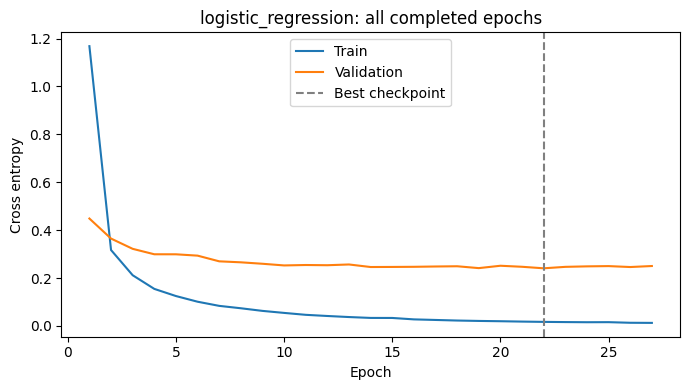

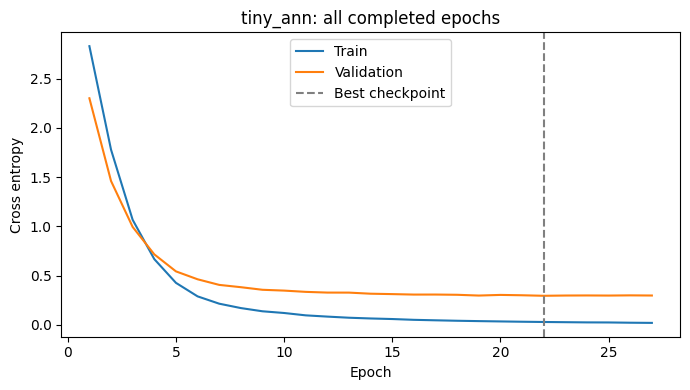

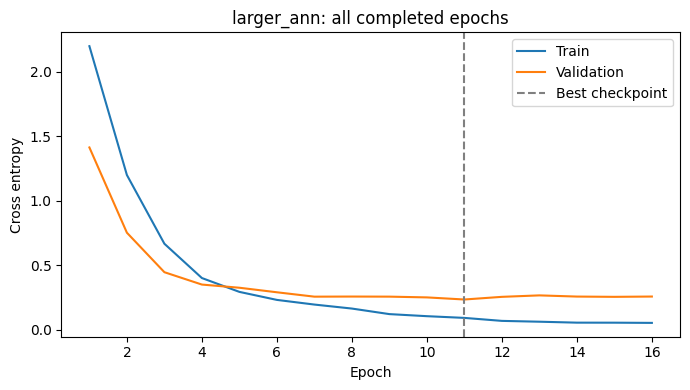

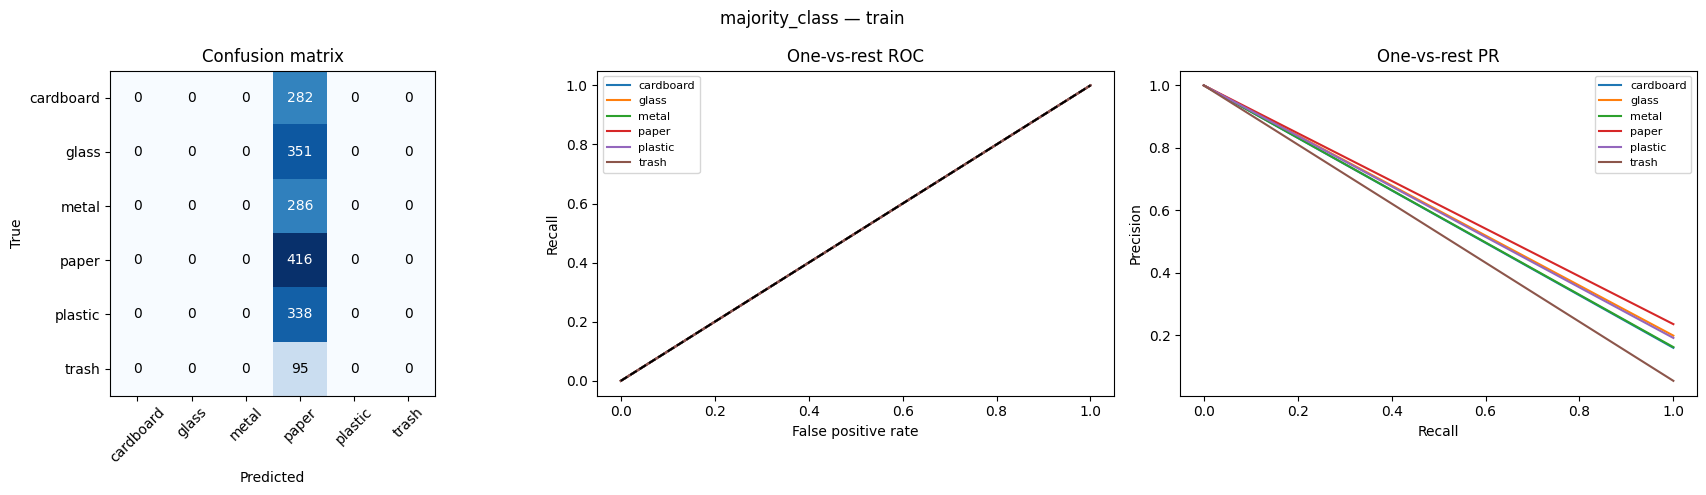

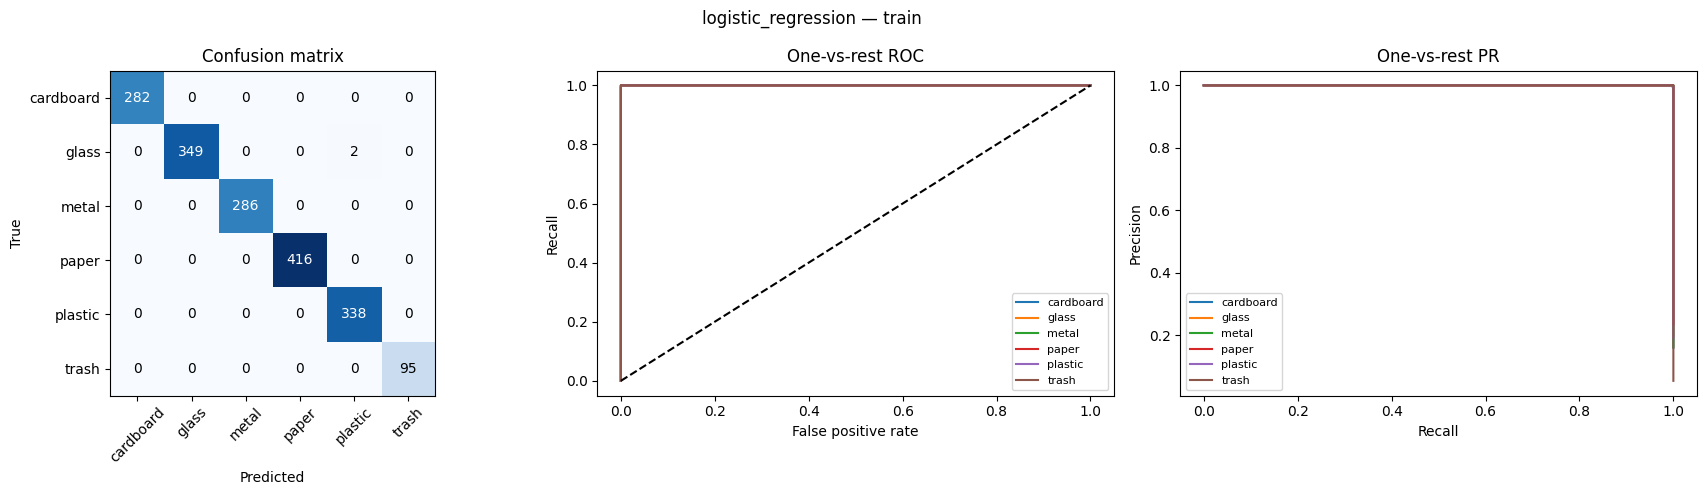

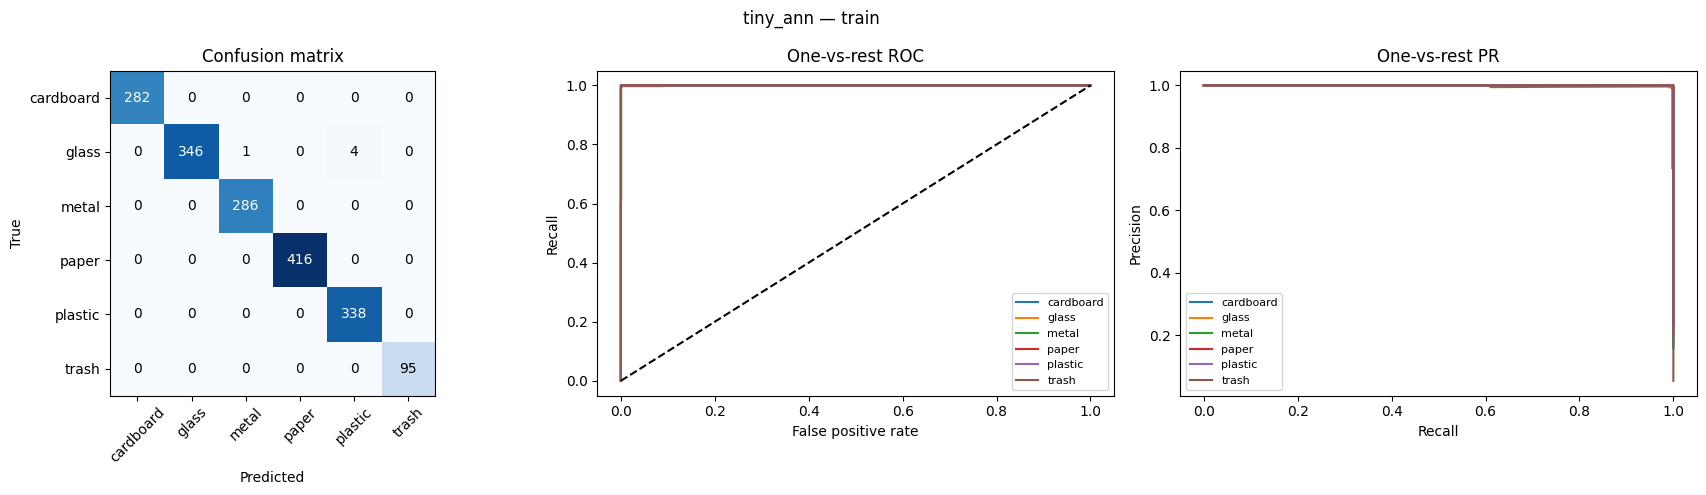

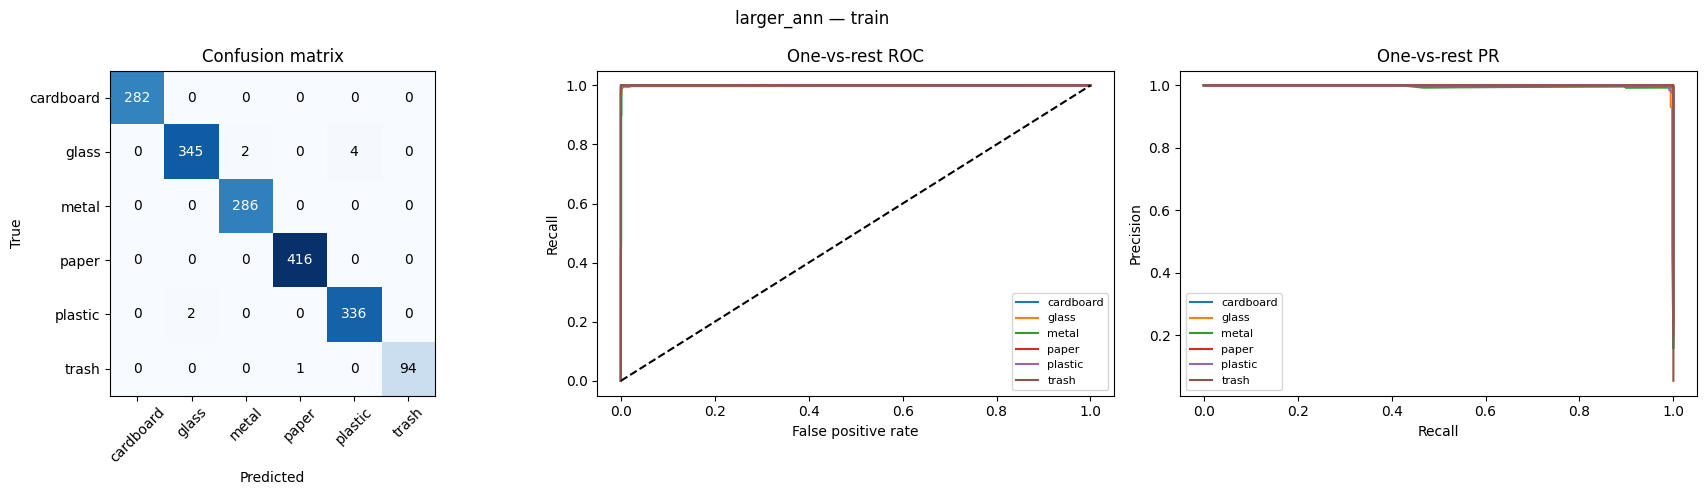

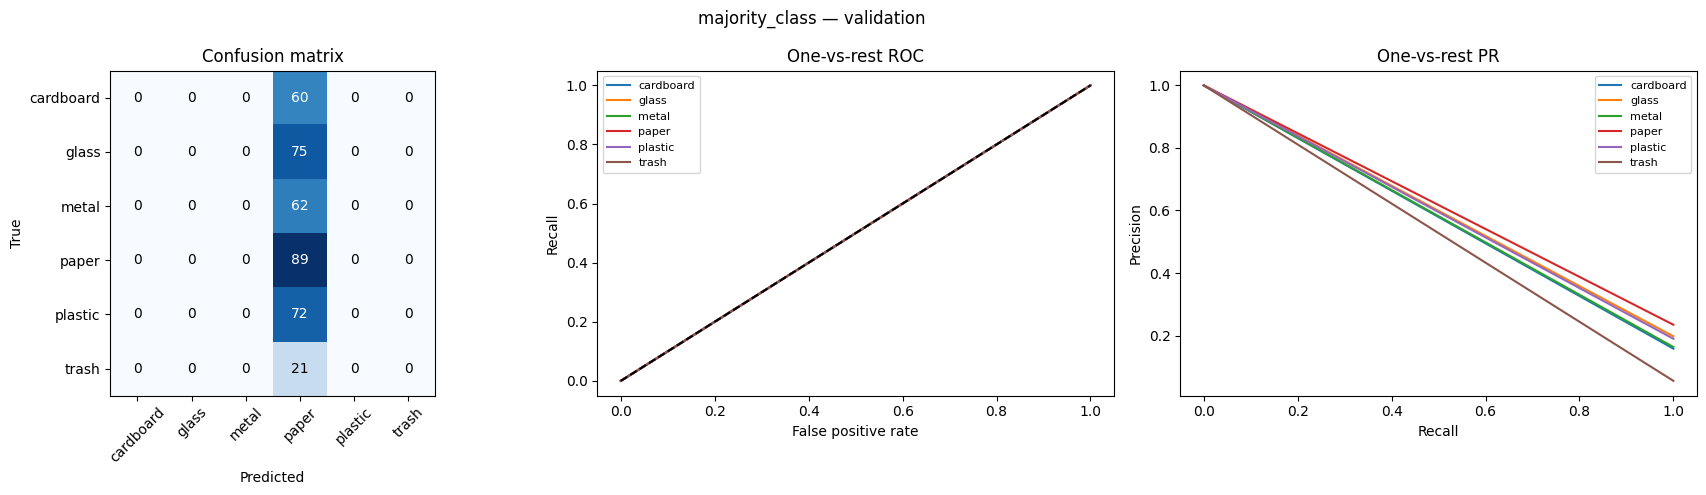

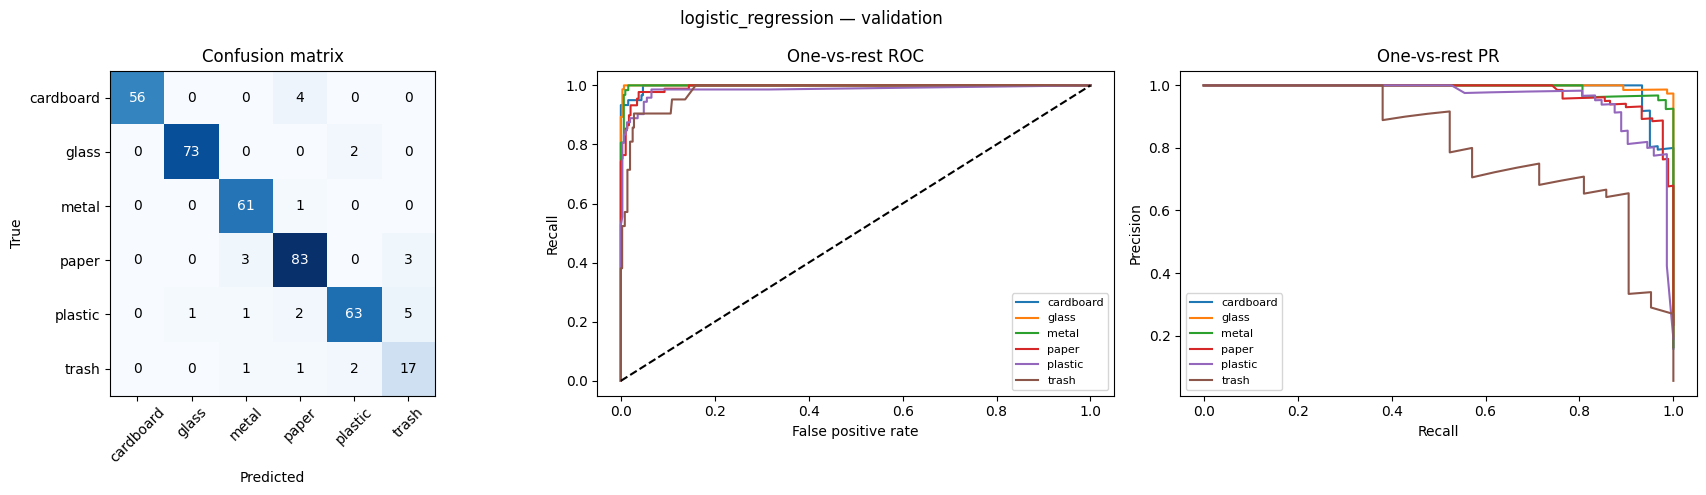

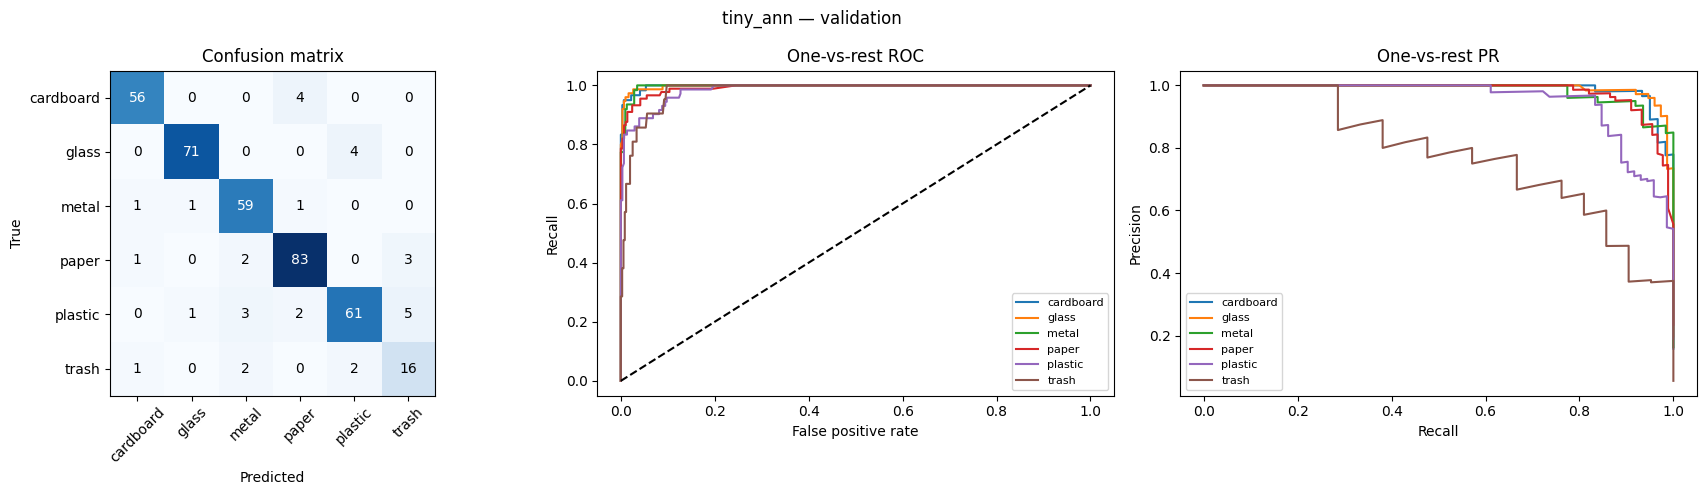

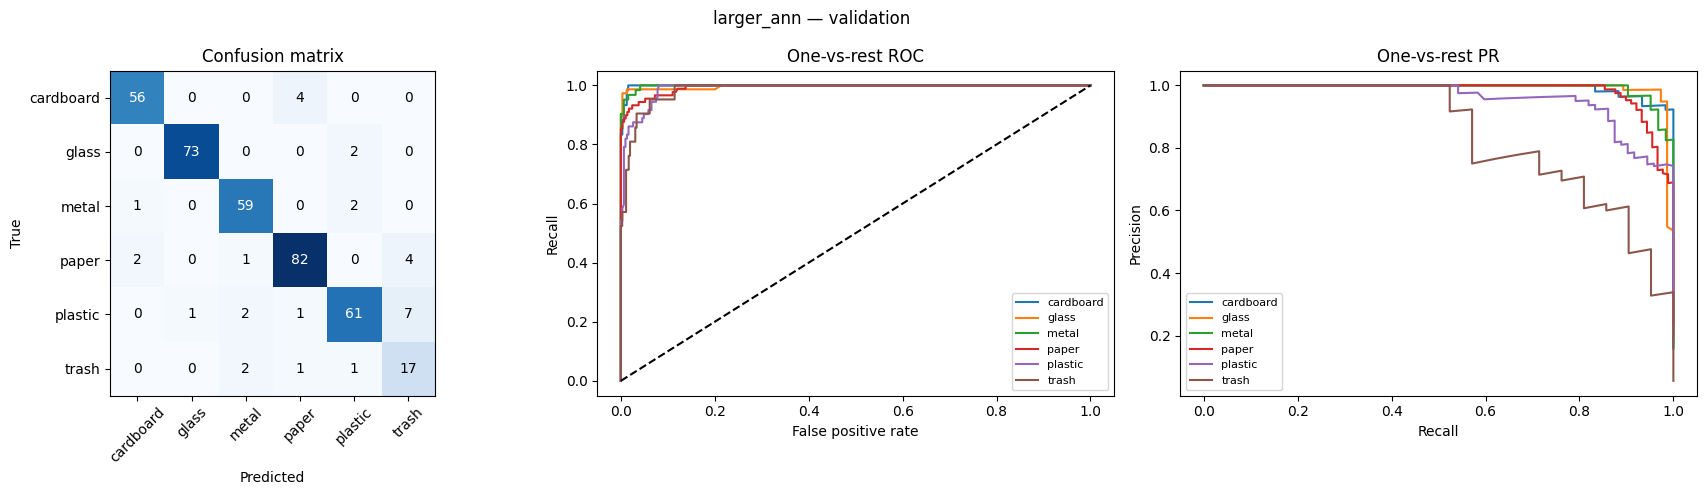

Saved artifacts: ['comparison.csv', 'comparison_all.csv', 'feature_extraction.json', 'final_test_results.json', 'larger_ann_best.keras', 'larger_ann_epochs.csv', 'larger_ann_history.json', 'larger_ann_learning_curve.png', 'larger_ann_train_metrics.png', 'larger_ann_validation_metrics.png', 'logistic_regression_best.keras', 'logistic_regression_epochs.csv', 'logistic_regression_history.json', 'logistic_regression_learning_curve.png', 'logistic_regression_train_metrics.png', 'logistic_regression_validation_metrics.png', 'majority_class_train_metrics.png', 'majority_class_validation_metrics.png', 'metrics.json', 'notebook_runtime.json', 'sample_image.png', 'spatial_logistic_regression_best.keras', 'spatial_logistic_regression_epochs.csv', 'spatial_logistic_regression_history.json', 'spatial_tiny_ann_best.keras', 'spatial_tiny_ann_epochs.csv', 'spatial_tiny_ann_history.json', 'split_manifest.json', 'tiny_ann_best.keras', 'tiny_ann_epochs.csv', 'tiny_ann_history.json', 'tiny_ann_learning_cu

In [43]:
plot_reports(results, histories, class_names, OUTPUT_DIR)
print('Saved artifacts:', [path.name for path in sorted(OUTPUT_DIR.iterdir())])
print('Finished. Test inference and scoring calls: 0.')
# Save and display full execution time so the downloaded notebook carries it.
elapsed_seconds = time.perf_counter() - notebook_started
runtime_report = {'execution_seconds': elapsed_seconds,
                  'execution_minutes': elapsed_seconds / 60., 'queue_time_included': False}
(OUTPUT_DIR / 'notebook_runtime.json').write_text(json.dumps(runtime_report, indent=2))
print(f'Notebook execution time: {elapsed_seconds / 60.:.2f} minutes ({elapsed_seconds:.1f} seconds).')


## 11. Spatial-feature experiments

Instead of using DINOv3's global pooled 768-dimensional vector, these experiments
use the spatial feature map. The feature map is reduced to a 2×2 grid and flattened
into a 3,072-dimensional vector, preserving coarse spatial information.

We compare the same classifier types on the spatial representation so the effect
of the representation can be evaluated separately from classifier complexity.


In [44]:
# Reload the original DINOv3 model because Step 7 replaced `backbone`
# with a pooled-only version.

spatial_backbone = tf.keras.models.load_model(model_file, compile=False)
spatial_backbone.trainable = False

print("Original outputs:", spatial_backbone.output.keys())
print("Feature-map shape:", spatial_backbone.output["feature_map"].shape)

Original outputs: dict_keys(['pooled', 'feature_map'])
Feature-map shape: (None, None, None, 768)


In [45]:
@tf.function(
    input_signature=[
        tf.TensorSpec(shape=(1, None, None, 3), dtype=tf.float32)
    ]
)
def spatial_infer(pixels):
    outputs = spatial_backbone(pixels, training=False)
    return tf.cast(outputs["feature_map"], tf.float32)


def spatial_2x2_vector(feature_map):
    # Reduce variable HxW spatial feature map to a fixed 2x2 grid
    pooled_grid = tf.image.resize(
        feature_map,
        size=(2, 2),
        method="area"
    )

    # 2 x 2 x 768 = 3072 features
    vector = tf.reshape(pooled_grid, (1, -1))
    return vector

In [46]:
sample = splits["train"][0]

pixels = preprocess_image(sample["image"])
feature_map = spatial_infer(pixels)
spatial_vector = spatial_2x2_vector(feature_map)

print("Feature map shape:", feature_map.shape)
print("Spatial vector shape:", spatial_vector.shape)

Feature map shape: (1, 12, 16, 768)
Spatial vector shape: (1, 3072)


In [47]:
import numpy as np
import time

def extract_spatial_features(split, split_name):
    features = np.zeros((len(split), 3072), dtype=np.float32)
    labels = np.zeros(len(split), dtype=np.int32)

    start = time.time()

    for i, example in enumerate(split):
        pixels = preprocess_image(example["image"])
        feature_map = spatial_infer(pixels)
        vector = spatial_2x2_vector(feature_map)

        features[i] = vector.numpy()[0]
        labels[i] = example["label"]

        if (i + 1) % 100 == 0 or (i + 1) == len(split):
            elapsed = time.time() - start
            print(
                f"{split_name}: {i + 1}/{len(split)} "
                f"({elapsed:.1f}s elapsed)"
            )

    return features, labels


X_train_spatial, y_train_spatial = extract_spatial_features(
    splits["train"], "train"
)

X_val_spatial, y_val_spatial = extract_spatial_features(
    splits["validation"], "validation"
)

print()
print("Train spatial:", X_train_spatial.shape)
print("Validation spatial:", X_val_spatial.shape)
print("Train labels:", y_train_spatial.shape)
print("Validation labels:", y_val_spatial.shape)

train: 100/1768 (4.3s elapsed)
train: 200/1768 (8.6s elapsed)
train: 300/1768 (12.8s elapsed)
train: 400/1768 (17.0s elapsed)
train: 500/1768 (21.3s elapsed)
train: 600/1768 (25.6s elapsed)
train: 700/1768 (29.8s elapsed)
train: 800/1768 (34.1s elapsed)
train: 900/1768 (38.4s elapsed)
train: 1000/1768 (42.7s elapsed)
train: 1100/1768 (47.0s elapsed)
train: 1200/1768 (51.3s elapsed)
train: 1300/1768 (55.5s elapsed)
train: 1400/1768 (59.8s elapsed)
train: 1500/1768 (64.1s elapsed)
train: 1600/1768 (68.3s elapsed)
train: 1700/1768 (72.6s elapsed)
train: 1768/1768 (75.5s elapsed)
validation: 100/379 (4.2s elapsed)
validation: 200/379 (8.4s elapsed)
validation: 300/379 (12.6s elapsed)
validation: 379/379 (16.0s elapsed)

Train spatial: (1768, 3072)
Validation spatial: (379, 3072)
Train labels: (1768,)
Validation labels: (379,)


In [48]:
np.save("/kaggle/working/X_train_spatial.npy", X_train_spatial)
np.save("/kaggle/working/y_train_spatial.npy", y_train_spatial)
np.save("/kaggle/working/X_val_spatial.npy", X_val_spatial)
np.save("/kaggle/working/y_val_spatial.npy", y_val_spatial)

print("Spatial feature cache saved.")

Spatial feature cache saved.


In [49]:
spatial_cache = {
    "train": (X_train_spatial, y_train_spatial),
    "validation": (X_val_spatial, y_val_spatial),
}

spatial_logistic_spec = {
    "name": "spatial_logistic_regression",
    "hidden_units": (),
    "learning_rate": 0.001,
    "wsd": False,
}

print("Training spatial logistic regression...")

spatial_logistic_head, spatial_logistic_history = train_head(
    spatial_logistic_spec,
    spatial_cache,
    len(class_names),
    OUTPUT_DIR,
    batch_size=BATCH_SIZE,
    epochs=MAX_EPOCHS,
    patience=PATIENCE,
    seed=SEED,
)

print({
    key: value
    for key, value in spatial_logistic_history.items()
    if key != "history"
})

Training spatial logistic regression...
Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


28/28 - 2s - 77ms/step - accuracy: 0.7551 - loss: 0.7454 - val_accuracy: 0.8865 - val_loss: 0.3416
Epoch 2/50
28/28 - 0s - 4ms/step - accuracy: 0.9457 - loss: 0.1797 - val_accuracy: 0.9129 - val_loss: 0.2916
Epoch 3/50
28/28 - 0s - 4ms/step - accuracy: 0.9734 - loss: 0.1048 - val_accuracy: 0.9129 - val_loss: 0.2600
Epoch 4/50
28/28 - 0s - 4ms/step - accuracy: 0.9796 - loss: 0.0768 - val_accuracy: 0.9314 - val_loss: 0.2283
Epoch 5/50
28/28 - 0s - 3ms/step - accuracy: 0.9887 - loss: 0.0541 - val_accuracy: 0.9261 - val_loss: 0.2330
Epoch 6/50
28/28 - 0s - 3ms/step - accuracy: 0.9893 - loss: 0.0507 - val_accuracy: 0.9393 - val_loss: 0.2473
Epoch 7/50
28/28 - 0s - 4ms/step - accuracy: 0.9915 - loss: 0.0386 - val_accuracy: 0.9314 - val_loss: 0.2201
Epoch 8/50
28/28 - 0s - 4ms/step - accuracy: 0.9955 - loss: 0.0289 - val_accuracy: 0.9420 - val_loss: 0.2186
Epoch 9/50
28/28 - 0s - 3ms/step - accuracy: 0.9972 - loss: 0.0237 - val_accuracy: 0.9235 - val_loss: 0.2224
Epoch 10/50
28/28 - 0s - 3ms/

In [50]:
spatial_results = {}

for split_name, (x, y) in spatial_cache.items():
    probabilities = spatial_logistic_head.predict(
        feature_dataset(x, y, BATCH_SIZE),
        verbose=0
    )

    spatial_results[split_name] = evaluate_probabilities(
        y,
        probabilities,
        class_names
    )

print("Spatial logistic regression results")

for split_name, report in spatial_results.items():
    print(
        split_name,
        "| accuracy:",
        round(report["accuracy"], 4),
        "| macro F1:",
        round(report["f1_macro"], 4),
        "| loss:",
        round(report["loss"], 4),
    )

Spatial logistic regression results
train | accuracy: 0.9989 | macro F1: 0.999 | loss: 0.0088
validation | accuracy: 0.942 | macro F1: 0.9282 | loss: 0.2154


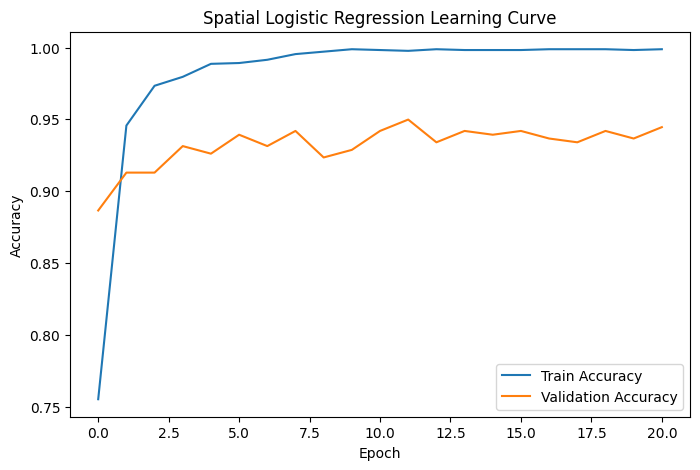

In [51]:
import matplotlib.pyplot as plt

history = spatial_logistic_history["history"]

plt.figure(figsize=(8, 5))
plt.plot(history["accuracy"], label="Train Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Spatial Logistic Regression Learning Curve")
plt.legend()
plt.show()

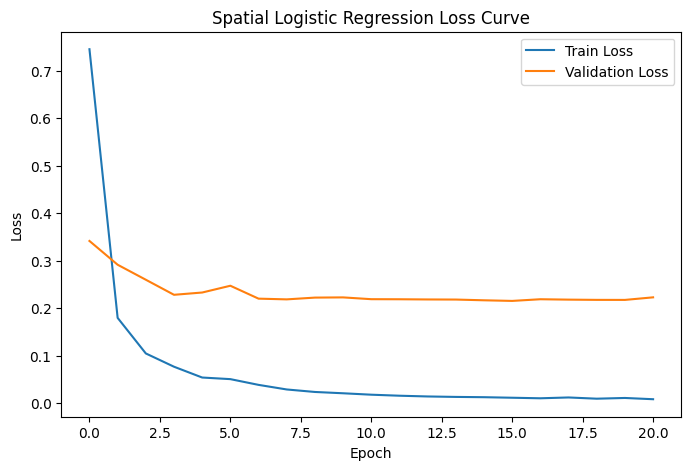

In [52]:
plt.figure(figsize=(8, 5))
plt.plot(history["loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Spatial Logistic Regression Loss Curve")
plt.legend()
plt.show()

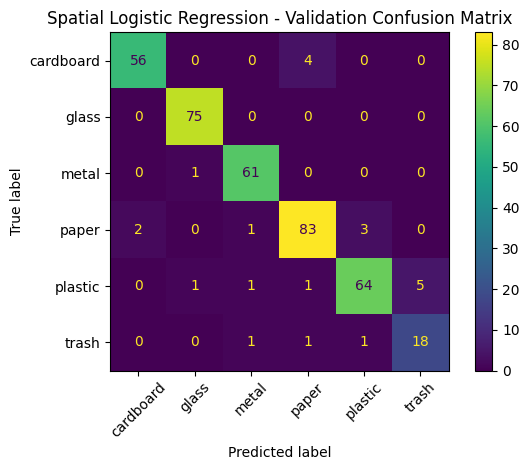

In [53]:
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

val_probs = spatial_logistic_head.predict(
    feature_dataset(
        X_val_spatial,
        y_val_spatial,
        BATCH_SIZE
    ),
    verbose=0
)

val_preds = np.argmax(val_probs, axis=1)

ConfusionMatrixDisplay.from_predictions(
    y_val_spatial,
    val_preds,
    display_labels=class_names,
    xticks_rotation=45
)

plt.title("Spatial Logistic Regression - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [54]:
spatial_tiny_spec = {
    "name": "spatial_tiny_ann",
    "hidden_units": (8,),
    "learning_rate": 0.001,
    "wsd": True,
}

print("Training spatial tiny ANN...")

spatial_tiny_head, spatial_tiny_history = train_head(
    spatial_tiny_spec,
    spatial_cache,
    len(class_names),
    OUTPUT_DIR,
    batch_size=BATCH_SIZE,
    epochs=MAX_EPOCHS,
    patience=PATIENCE,
    seed=SEED,
)

print({
    key: value
    for key, value in spatial_tiny_history.items()
    if key != "history"
})

Training spatial tiny ANN...
Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


28/28 - 2s - 88ms/step - accuracy: 0.2506 - loss: 1.7837 - val_accuracy: 0.3588 - val_loss: 1.4902
Epoch 2/50
28/28 - 0s - 4ms/step - accuracy: 0.4966 - loss: 1.2427 - val_accuracy: 0.6148 - val_loss: 1.0174
Epoch 3/50
28/28 - 0s - 4ms/step - accuracy: 0.7913 - loss: 0.6396 - val_accuracy: 0.8628 - val_loss: 0.4838
Epoch 4/50
28/28 - 0s - 4ms/step - accuracy: 0.9231 - loss: 0.2752 - val_accuracy: 0.9024 - val_loss: 0.3097
Epoch 5/50
28/28 - 0s - 4ms/step - accuracy: 0.9627 - loss: 0.1578 - val_accuracy: 0.9050 - val_loss: 0.2736
Epoch 6/50
28/28 - 0s - 4ms/step - accuracy: 0.9723 - loss: 0.1269 - val_accuracy: 0.9261 - val_loss: 0.2520
Epoch 7/50
28/28 - 0s - 4ms/step - accuracy: 0.9893 - loss: 0.0753 - val_accuracy: 0.9340 - val_loss: 0.2191
Epoch 8/50
28/28 - 0s - 4ms/step - accuracy: 0.9910 - loss: 0.0577 - val_accuracy: 0.9314 - val_loss: 0.2080
Epoch 9/50
28/28 - 0s - 3ms/step - accuracy: 0.9949 - loss: 0.0452 - val_accuracy: 0.9340 - val_loss: 0.2113
Epoch 10/50
28/28 - 0s - 4ms/

In [55]:
spatial_tiny_results = {}

for split_name, (x, y) in spatial_cache.items():
    probabilities = spatial_tiny_head.predict(
        feature_dataset(x, y, BATCH_SIZE),
        verbose=0
    )

    spatial_tiny_results[split_name] = evaluate_probabilities(
        y,
        probabilities,
        class_names
    )

print("Spatial tiny ANN results")

for split_name, report in spatial_tiny_results.items():
    print(
        split_name,
        "| accuracy:",
        round(report["accuracy"], 4),
        "| macro F1:",
        round(report["f1_macro"], 4),
        "| loss:",
        round(report["loss"], 4),
    )

Spatial tiny ANN results
train | accuracy: 0.9989 | macro F1: 0.999 | loss: 0.0193
validation | accuracy: 0.9288 | macro F1: 0.9229 | loss: 0.195


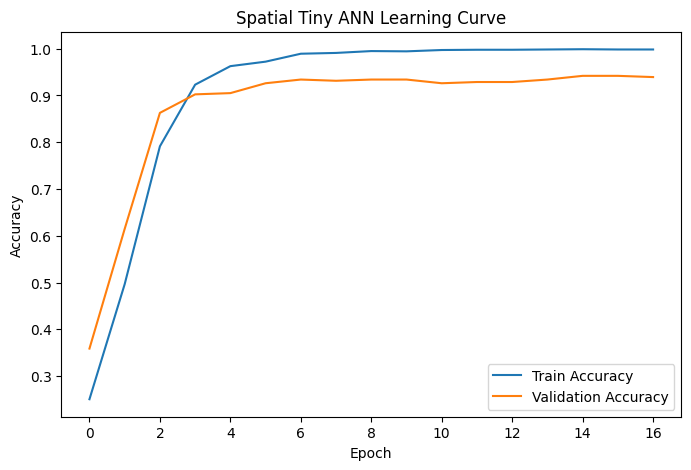

In [56]:
history = spatial_tiny_history["history"]

plt.figure(figsize=(8, 5))
plt.plot(history["accuracy"], label="Train Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Spatial Tiny ANN Learning Curve")
plt.legend()
plt.show()

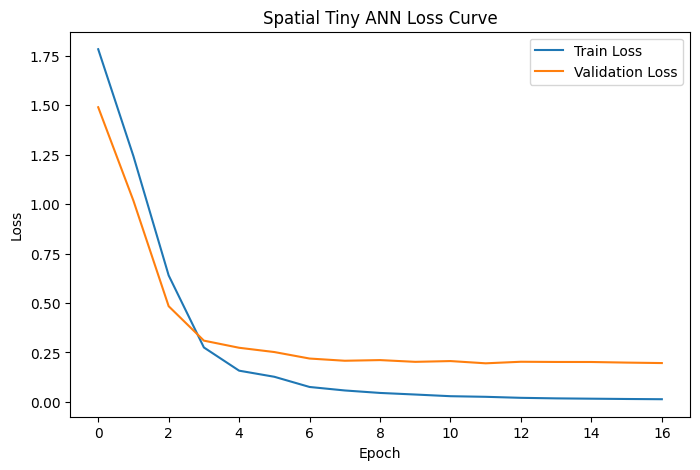

In [57]:
plt.figure(figsize=(8, 5))
plt.plot(history["loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Spatial Tiny ANN Loss Curve")
plt.legend()
plt.show()

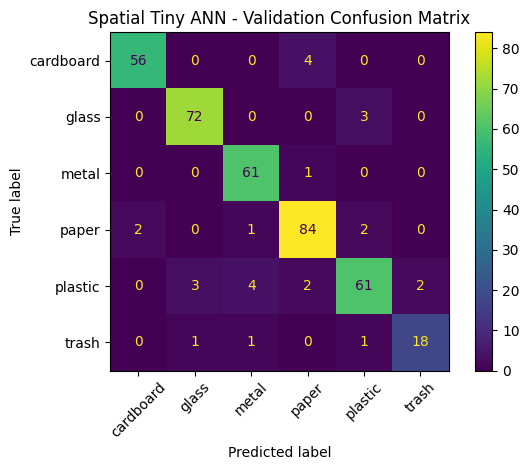

In [58]:
val_probs_tiny = spatial_tiny_head.predict(
    feature_dataset(
        X_val_spatial,
        y_val_spatial,
        BATCH_SIZE
    ),
    verbose=0
)

val_preds_tiny = np.argmax(val_probs_tiny, axis=1)

ConfusionMatrixDisplay.from_predictions(
    y_val_spatial,
    val_preds_tiny,
    display_labels=class_names,
    xticks_rotation=45
)

plt.title("Spatial Tiny ANN - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [59]:
import pandas as pd

comparison_all = pd.DataFrame([
    {
        "model": "Majority baseline",
        "representation": "None",
        "val_accuracy": 0.2348,
        "val_macro_f1": 0.0635,
    },
    {
        "model": "Pooled logistic",
        "representation": "Global pooled (768)",
        "val_accuracy": 0.9314,
        "val_macro_f1": 0.9110,
    },
    {
        "model": "Pooled tiny ANN",
        "representation": "Global pooled (768)",
        "val_accuracy": 0.9129,
        "val_macro_f1": 0.8900,
    },
    {
        "model": "Pooled larger ANN",
        "representation": "Global pooled (768)",
        "val_accuracy": 0.9182,
        "val_macro_f1": 0.8940,
    },
    {
        "model": "Spatial logistic",
        "representation": "2x2 spatial (3072)",
        "val_accuracy": 0.9420,
        "val_macro_f1": 0.9282,
    },
    {
        "model": "Spatial tiny ANN",
        "representation": "2x2 spatial (3072)",
        "val_accuracy": 0.9288,
        "val_macro_f1": 0.9229,
    },
])

comparison_all = comparison_all.sort_values(
    by="val_macro_f1",
    ascending=False
).reset_index(drop=True)

comparison_all

,model,representation,val_accuracy,val_macro_f1
0,Spatial logistic,2x2 spatial (3072),0.9420,0.9282
1,Spatial tiny ANN,2x2 spatial (3072),0.9288,0.9229
2,Pooled logistic,Global pooled (768),0.9314,0.9110
3,Pooled larger ANN,Global pooled (768),0.9182,0.8940
4,Pooled tiny ANN,Global pooled (768),0.9129,0.8900
5,Majority baseline,None,0.2348,0.0635


In [60]:
comparison_all.to_csv(
    "/kaggle/working/outputs/comparison_all.csv",
    index=False
)

print("Saved combined comparison table.")

Saved combined comparison table.


## 12. Final held-out test evaluation

The spatial logistic regression model was selected using validation performance.
The held-out test set is evaluated once here after model selection. No further
model tuning is performed using test results.

In [61]:
X_test_spatial, y_test_spatial = extract_spatial_features(
    splits["test"],
    "test"
)

print("Test spatial:", X_test_spatial.shape)
print("Test labels:", y_test_spatial.shape)

test: 100/380 (4.9s elapsed)
test: 200/380 (9.2s elapsed)
test: 300/380 (13.4s elapsed)
test: 380/380 (16.9s elapsed)
Test spatial: (380, 3072)
Test labels: (380,)


In [62]:
test_probs = spatial_logistic_head.predict(
    feature_dataset(
        X_test_spatial,
        y_test_spatial,
        BATCH_SIZE
    ),
    verbose=0
)

test_results = evaluate_probabilities(
    y_test_spatial,
    test_probs,
    class_names
)

print("FINAL HELD-OUT TEST RESULTS")
print("Accuracy:", round(test_results["accuracy"], 4))
print("Macro F1:", round(test_results["f1_macro"], 4))
print("Loss:", round(test_results["loss"], 4))
print("PR AUC:", round(test_results["pr_auc_macro"], 4))
print("ROC AUC:", round(test_results["roc_auc_macro"], 4))

FINAL HELD-OUT TEST RESULTS
Accuracy: 0.9447
Macro F1: 0.939
Loss: 0.2313
PR AUC: 0.9757
ROC AUC: 0.9935


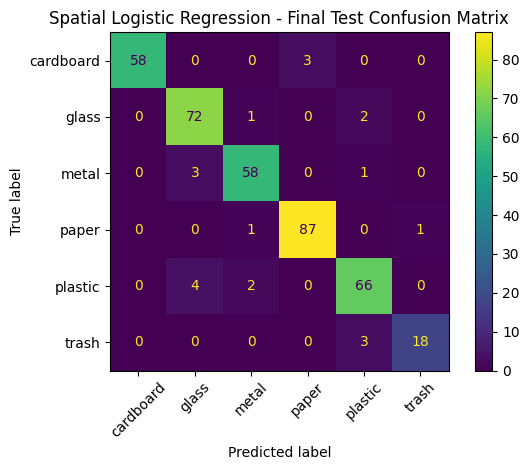

In [63]:
test_preds = np.argmax(test_probs, axis=1)

ConfusionMatrixDisplay.from_predictions(
    y_test_spatial,
    test_preds,
    display_labels=class_names,
    xticks_rotation=45
)

plt.title("Spatial Logistic Regression - Final Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [64]:
import json

with open(
    "/kaggle/working/outputs/final_test_results.json",
    "w"
) as f:
    json.dump(test_results, f, indent=2)

np.save(
    "/kaggle/working/X_test_spatial.npy",
    X_test_spatial
)

np.save(
    "/kaggle/working/y_test_spatial.npy",
    y_test_spatial
)

print("Final test results saved.")

Final test results saved.
